
# MMM Case Study — Regression Baseline

## Objective
Estimate the relationship between marketing spending and
revenue using synthetic data from 48 geographic markets.

## Models
1. Single-market linear regression
2. Pooled regression across 48 markets
3. Geographic fixed-effects regression
4. Fixed effects with business controls

## Key Findings
- Initial pooled spending coefficient: 14.90
- After geographic fixed effects: 10.80
- After business controls: 3.01
- Final model R²: 0.703
- Clustered 95% confidence interval: [2.46, 3.57]

## Limitations
These are observational estimates, not verified causal ROI.
Adstock, saturation, and channel-level effects are not yet modeled.

## Next
Implement Bayesian MMM using Google Meridian.


In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/rahitushar1/marketing-measurement-lab/main/mmm_geo_weekly.csv"
df = pd.read_csv(url)

print(df.shape)
display(df.head())



(7488, 19)


,week_start,geo_id,orders,revenue_cents,new_orders,eligible_audience,organic_queries,competitor_index_bps,promotion_discount_bps,list_price_index_bps,search_spend_cents,search_impressions,search_clicks,social_spend_cents,social_impressions,social_clicks,display_spend_cents,display_impressions,display_clicks
0,2023-01-02,0,22,120392,19,517.428571,892,10133.857143,741.000000,9783.857143,4066,178,25,3068,1094,23,533,388,7
1,2023-01-02,1,19,117182,12,384.285714,699,12288.714286,0.000000,10251.571429,2290,113,13,2582,712,9,404,267,3
2,2023-01-02,2,23,133355,17,481.571429,897,7888.714286,473.142857,10034.857143,1225,80,9,2860,1011,15,670,506,10
3,2023-01-02,3,16,120402,9,530.142857,947,10587.428571,157.714286,10343.857143,2447,104,14,3990,1137,18,744,472,7
4,2023-01-02,4,14,96286,12,387.714286,778,11207.571429,0.000000,9693.714286,1595,76,10,1765,542,8,619,452,1


In [ ]:
# Convert revenue from cents to dollars
df["revenue_usd"] = df["revenue_cents"] / 100

# Combine spending across three channels
df["total_spend_usd"] = (
    df["search_spend_cents"]
    + df["social_spend_cents"]
    + df["display_spend_cents"]
) / 100

# Inspect the results
display(df[["week_start", "geo_id", "revenue_usd", "total_spend_usd"]].head())


,week_start,geo_id,revenue_usd,total_spend_usd
0,2023-01-02,0,1203.92,76.67
1,2023-01-02,1,1171.82,52.76
2,2023-01-02,2,1333.55,47.55
3,2023-01-02,3,1204.02,71.81
4,2023-01-02,4,962.86,39.79


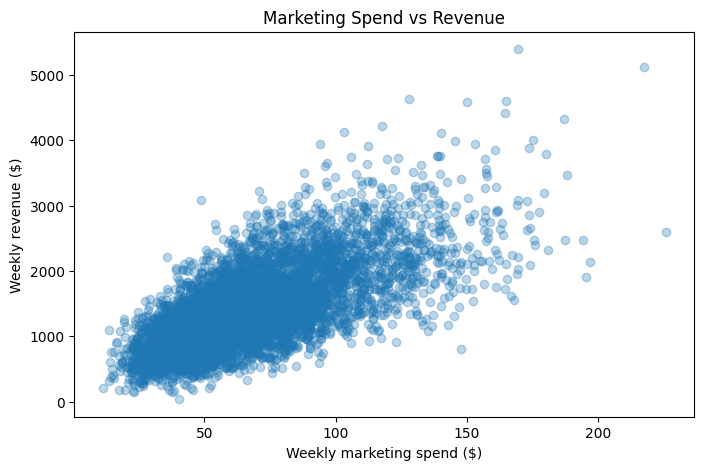

In [ ]:

import matplotlib.pyplot as plt

# Select the first 120 weeks, before the experiment
weeks = sorted(df["week_start"].unique())[:120]
df_pre = df[df["week_start"].isin(weeks)]

# Create a scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df_pre["total_spend_usd"],
    df_pre["revenue_usd"],
    alpha=0.3
)

plt.xlabel("Weekly marketing spend ($)")
plt.ylabel("Weekly revenue ($)")
plt.title("Marketing Spend vs Revenue")
plt.show()


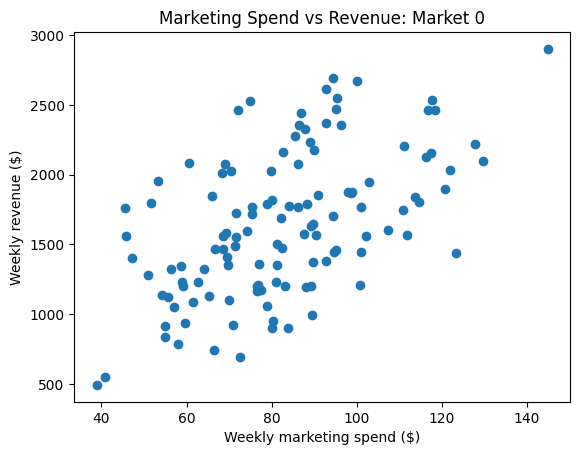

In [ ]:

# Select observations from Market 0
geo0 = df_pre[df_pre["geo_id"] == 0]

# Plot spending against revenue within this market
plt.scatter(geo0["total_spend_usd"], geo0["revenue_usd"])

plt.xlabel("Weekly marketing spend ($)")
plt.ylabel("Weekly revenue ($)")
plt.title("Marketing Spend vs Revenue: Market 0")
plt.show()


In [ ]:

geo0["total_spend_usd"].corr(geo0["revenue_usd"])


np.float64(0.5455865926873974)

In [ ]:

import statsmodels.formula.api as smf

model = smf.ols(
    "revenue_usd ~ total_spend_usd",
    data=geo0
).fit()

print("Intercept:", round(model.params["Intercept"], 2))
print("Spend coefficient:", round(model.params["total_spend_usd"], 2))
print("R-squared:", round(model.rsquared, 3))


Intercept: 527.84
Spend coefficient: 13.5
R-squared: 0.298


In [ ]:

model_all = smf.ols(
    "revenue_usd ~ total_spend_usd",
    data=df_pre
).fit()

print("Intercept:", round(model_all.params["Intercept"], 2))
print("Spend coefficient:", round(model_all.params["total_spend_usd"], 2))
print("R-squared:", round(model_all.rsquared, 3))
print("Observations:", int(model_all.nobs))


Intercept: 415.0
Spend coefficient: 14.9
R-squared: 0.467
Observations: 5760


In [ ]:

# Model 3: Geographic fixed effects
model_geo = smf.ols(
    "revenue_usd ~ total_spend_usd + C(geo_id)",
    data=df_pre
).fit()

print("Intercept (Geo 0):", round(model_geo.params["Intercept"], 2))
print("Spend coefficient:", round(model_geo.params["total_spend_usd"], 2))
print("R-squared:", round(model_geo.rsquared, 3))
print("Observations:", int(model_geo.nobs))


Intercept (Geo 0): 751.42
Spend coefficient: 10.8
R-squared: 0.59
Observations: 5760


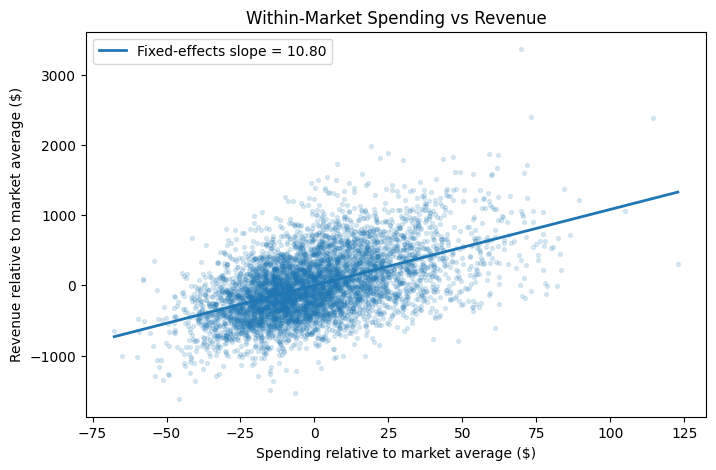

In [ ]:

# Calculate each market's average values
geo_means = df_pre.groupby("geo_id")[
    ["total_spend_usd", "revenue_usd"]
].transform("mean")

# Subtract the market averages
x = df_pre["total_spend_usd"] - geo_means["total_spend_usd"]
y = df_pre["revenue_usd"] - geo_means["revenue_usd"]

# Plot the within-market relationship
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.15, s=8)

slope = model_geo.params["total_spend_usd"]
plt.plot([x.min(), x.max()],
         [slope * x.min(), slope * x.max()],
         linewidth=2, label=f"Fixed-effects slope = {slope:.2f}")

plt.xlabel("Spending relative to market average ($)")
plt.ylabel("Revenue relative to market average ($)")
plt.title("Within-Market Spending vs Revenue")
plt.legend()
plt.show()


In [ ]:

# Display the estimated intercept for each geo
base = model_geo.params["Intercept"]

for geo in range(48):
    adjustment = model_geo.params.get(f"C(geo_id)[T.{geo}]", 0)
    print(f"Geo {geo}: ${base + adjustment:,.2f}")


Geo 0: $751.42
Geo 1: $590.45
Geo 2: $1,039.35
Geo 3: $803.52
Geo 4: $451.06
Geo 5: $818.56
Geo 6: $520.12
Geo 7: $539.93
Geo 8: $785.56
Geo 9: $609.58
Geo 10: $900.38
Geo 11: $528.01
Geo 12: $731.63
Geo 13: $658.38
Geo 14: $521.66
Geo 15: $608.32
Geo 16: $1,179.23
Geo 17: $912.62
Geo 18: $830.46
Geo 19: $424.60
Geo 20: $430.56
Geo 21: $952.04
Geo 22: $692.63
Geo 23: $633.33
Geo 24: $593.21
Geo 25: $646.21
Geo 26: $701.00
Geo 27: $709.04
Geo 28: $451.49
Geo 29: $730.62
Geo 30: $277.72
Geo 31: $680.04
Geo 32: $667.67
Geo 33: $720.14
Geo 34: $593.50
Geo 35: $1,000.57
Geo 36: $293.20
Geo 37: $274.70
Geo 38: $489.09
Geo 39: $501.42
Geo 40: $501.10
Geo 41: $644.68
Geo 42: $1,631.15
Geo 43: $726.39
Geo 44: $740.89
Geo 45: $1,029.84
Geo 46: $1,172.52
Geo 47: $783.93


In [ ]:

# Model 4: Geo fixed effects + business controls
model_controls = smf.ols(
    """revenue_usd ~ total_spend_usd
    + organic_queries
    + promotion_discount_bps
    + list_price_index_bps
    + competitor_index_bps
    + C(geo_id)""",
    data=df_pre
).fit()

# Compare Model 3 and Model 4
print("MODEL 3: GEO FIXED EFFECTS")
print("Spend coefficient:", round(model_geo.params["total_spend_usd"], 2))
print("R-squared:", round(model_geo.rsquared, 3))

print("\nMODEL 4: WITH BUSINESS CONTROLS")
print("Spend coefficient:", round(model_controls.params["total_spend_usd"], 2))
print("R-squared:", round(model_controls.rsquared, 3))
print("Observations:", int(model_controls.nobs))


# Display coefficients for marketing spend and controls
variables = [
    "total_spend_usd",
    "organic_queries",
    "promotion_discount_bps",
    "list_price_index_bps",
    "competitor_index_bps"
]

# Show estimated coefficient and p-value for each
results = pd.DataFrame({
    "Coefficient": model_controls.params[variables],
    "P-value": model_controls.pvalues[variables]
})

display(results.round(4))



MODEL 3: GEO FIXED EFFECTS
Spend coefficient: 10.8
R-squared: 0.59

MODEL 4: WITH BUSINESS CONTROLS
Spend coefficient: 3.01
R-squared: 0.703
Observations: 5760


,Coefficient,P-value
total_spend_usd,3.0147,0.0000
organic_queries,1.3936,0.0000
promotion_discount_bps,-0.0523,0.0023
list_price_index_bps,-0.0775,0.0000
competitor_index_bps,-0.0491,0.0000


In [ ]:

# Account for repeated observations within markets
robust = model_controls.get_robustcov_results(
    cov_type="cluster",
    groups=df_pre["geo_id"]
)

# Locate the advertising coefficient
i = robust.model.exog_names.index("total_spend_usd")

print("Spend coefficient:", round(robust.params[i], 2))
print("95% confidence interval:", robust.conf_int()[i].round(2))
print("P-value:", round(robust.pvalues[i], 4))


Spend coefficient: 3.01
95% confidence interval: [2.46 3.57]
P-value: 0.0


In [ ]:

# Create a separate table for Meridian preparation
meridian_inputs = df.copy()

# Convert each channel's spending into dollars
for channel in ["search", "social", "display"]:
    meridian_inputs[f"{channel}_spend_usd"] = (
        meridian_inputs[f"{channel}_spend_cents"] / 100
    )

# Inspect the media inputs
display(meridian_inputs[[
    "week_start", "geo_id", "revenue_usd",
    "search_impressions", "search_spend_usd",
    "social_impressions", "social_spend_usd",
    "display_impressions", "display_spend_usd"
]].head())


,week_start,geo_id,revenue_usd,search_impressions,search_spend_usd,social_impressions,social_spend_usd,display_impressions,display_spend_usd
0,2023-01-02,0,1203.92,178,40.66,1094,30.68,388,5.33
1,2023-01-02,1,1171.82,113,22.90,712,25.82,267,4.04
2,2023-01-02,2,1333.55,80,12.25,1011,28.60,506,6.70
3,2023-01-02,3,1204.02,104,24.47,1137,39.90,472,7.44
4,2023-01-02,4,962.86,76,15.95,542,17.65,452,6.19


In [ ]:

from google.colab import files

uploaded = files.upload()

geos = pd.read_csv("geos.csv")

display(geos.head())


In [ ]:

# Merge population into our Meridian dataset
meridian_inputs = meridian_inputs.merge(
    geos[["geo_id", "modeled_population"]],
    on="geo_id",
    how="left",
    validate="many_to_one"
)

# Inspect the result
print("Dataset shape:", meridian_inputs.shape)
print("Missing populations:",
      meridian_inputs["modeled_population"].isna().sum())

display(meridian_inputs[
    ["week_start", "geo_id", "modeled_population",
     "revenue_usd", "search_spend_usd",
     "social_spend_usd", "display_spend_usd"]
].head())


In [ ]:

%pip install -q "google-meridian==2.2.0"

import meridian
print("Meridian version:", meridian.__version__)
